In [ ]:
import os
import scanpy as sc
import anndata as ad
import logging

In [ ]:
sc.settings.set_figure_params(dpi=50, dpi_save=300, figsize=(9,6), facecolor="white")

In [ ]:
logging.basicConfig(level=logging.INFO)

def load_10x_folders(data_path, cache=True):
    adata_dict = {}
    
    try:
        items = os.listdir(data_path)
    except Exception as e:
        logging.error(f"Failed to list items in {data_path}: {e}")
        return adata_dict
    
    for item_name in items:
        item_path = os.path.join(data_path, item_name)
        
        if os.path.isdir(item_path):
            try:
                adata = sc.read_10x_mtx(item_path, var_names='gene_symbols', cache=cache)
                adata.var_names_make_unique()
                adata_dict[item_name] = adata
                logging.info(f"Successfully loaded folder: {item_name}")
            except Exception as e:
                logging.warning(f"Failed to load folder {item_name}: {e}")
        
        elif item_path.endswith(".h5"):
            try:
                adata = sc.read_10x_h5(item_path)
                adata.var_names_make_unique()
                adata_dict[item_name] = adata
                logging.info(f"Successfully loaded h5 file: {item_name}")
            except Exception as e:
                logging.warning(f"Failed to load h5 file {item_name}: {e}")
    
    return adata_dict

In [3]:
dataDir = "/home/fugui/publicData/SingleCellDatabase/GSE163558_GastricCancer/01_matrix/"

In [4]:
adata_dict = load_10x_folders(dataDir)

Successfully loaded folder: GSM5004180_PT1
Successfully loaded folder: GSM5004181_PT2
Successfully loaded folder: GSM5004182_PT3
Successfully loaded folder: GSM5004183_NT1
Successfully loaded folder: GSM5004184_LN1
Successfully loaded folder: GSM5004185_LN2
Successfully loaded folder: GSM5004186_O1
Successfully loaded folder: GSM5004187_P1
Successfully loaded folder: GSM5004188_Li1
Successfully loaded folder: GSM5004189_Li2


In [5]:
adata = ad.concat(adata_dict, label="sample")
adata.obs_names_make_unique()
print(adata.obs["sample"].value_counts())
adata

sample
GSM5004189_Li2    11164
GSM5004181_PT2     9226
GSM5004185_LN2     7940
GSM5004186_O1      5937
GSM5004187_P1      5277
GSM5004184_LN1     4227
GSM5004182_PT3     3925
GSM5004180_PT1     2866
GSM5004183_NT1     2777
GSM5004188_Li1     1348
Name: count, dtype: int64


/home/fugui/miniconda3/envs/r433/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 54687 × 33538
    obs: 'sample'

### Quality Control


In [ ]:
def specificGeneExpression(adata):
    # Mitochondrial genes
    adata.var["mt"] = adata.var_names.str.startswith(("MT-", "mt-"))
    # Mitochondrial ribosomal and ribosomal genes
    adata.var["rb"] = adata.var_names.str.contains("^M?[Rr][Pp][LSls]")
    # Hemoglobin protein genes
    adata.var["hb"] = adata.var_names.str.contains("^H[Bb][^(Pp)]")
    sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "rb", "hb"], 
                               percent_top=None, log1p=False, inplace=True)
    return adata

In [7]:
%%time
adata = specificGeneExpression(adata)
adata

CPU times: user 1.42 s, sys: 313 ms, total: 1.73 s
Wall time: 1.39 s


AnnData object with n_obs × n_vars = 54687 × 33538
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

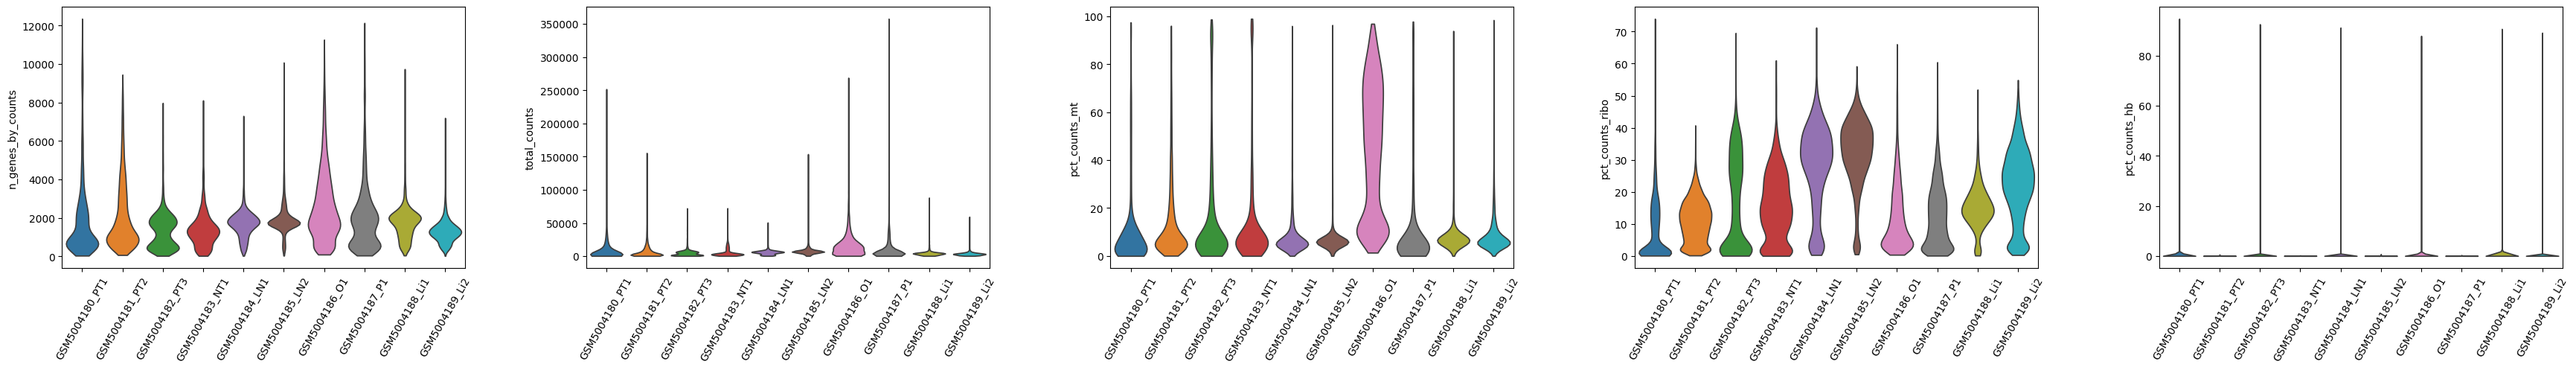

In [8]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb"],
             groupby='sample', jitter=0.4, size=0, multi_panel=True, rotation=60)

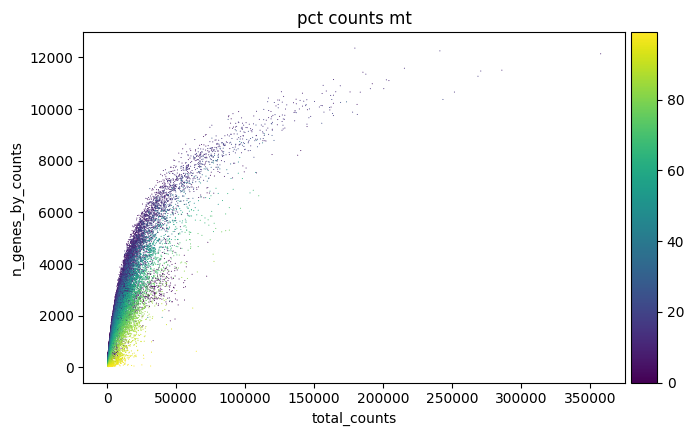

In [9]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [ ]:
dissociation_genes = (
    'Actg1', 'Btg1', 'Cxcl1', 'Dnajb4', 'Errfi1', 'H3f3b', 'Hspb1', 'Irf1', 
    'Klf6', 'Mir22hg', 'Nfkbia', 'Pcf11', 'Pxdc1', 'Sdc4', 'Srf', 'Tpm3', 
    'Usp2', 'Gadd45g', 'Ankrd1', 'Btg2', 'Cyr61', 'Dusp1', 'Fam132b', 'Hipk3',
    'Hsph1', 'Irf8', 'Klf9', 'Mt1', 'Nfkbiz', 'Pde4b', 'Rap1b', 'Serpine1', 
    'Srsf5', 'Tppp3', 'Wac', 'Hspe1', 'Arid5a', 'Ccnl1', 'Dcn', 'Dusp8', 
    'Fos', 'Hsp90aa1', 'Id3', 'Itpkc', 'Litaf', 'Mt2', 'Nop58', 'Per1', 
    'Rassf1', 'Skil', 'Srsf7', 'Tra2a', 'Zc3h12a', 'Ier5', 'Atf3', 'Ccrn4l',
    'Ddx3x', 'Egr1', 'Fosb', 'Hsp90ab1', 'Idi1', 'Jun', 'Lmna', 'Myadm', 
    'Nppc', 'Phlda1', 'Rhob', 'Slc10a6', 'Stat3', 'Tra2b', 'Zfand5', 'Kcne4',
    'Atf4', 'Cebpb', 'Ddx5', 'Egr2', 'Fosl2', 'Hspa1a', 'Ier2', 'Junb',
    'Maff', 'Myc', 'Nr4a1', 'Pnp', 'Rhoh', 'Slc38a2', 'Tagln2', 'Trib1',
    'Zfp36', 'Bag3', 'Cebpd', 'Des', 'Eif1', 'Gadd45a', 'Hspa1b', 'Ier3',
    'Jund', 'Mafk', 'Myd88', 'Odc1', 'Pnrc1', 'Ripk1', 'Slc41a1', 
    'Tiparp', 'Tubb4b', 'Zfp36l1', 'Bhlhe40', 'Cebpg', 'Dnaja1', 'Eif5',
    'Gcc1', 'Hspa5', 'Ifrd1', 'Klf2', 'Mcl1', 'Nckap5l', 'Osgin1', 
    'Ppp1cc', 'Sat1', 'Socs3', 'Tnfaip3', 'Tubb6', 'Zfp36l2', 'Brd2',
    'Csrnp1', 'Dnajb1', 'Erf', 'Gem', 'Hspa8', 'Il6', 'Klf4', 'Midn',
    'Ncoa7', 'Oxnad1', 'Ppp1r15a', 'Sbno2', 'Sqstm1', 'Tnfaip6', 'Ubc', 'Zyx')

#### manual thresholds for filtering cells

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_cells(adata, max_genes=5000)
adata = adata[adata.obs['pct_counts_mt'] < 20, :]
adata

View of AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'sample_colors'

#### filtering based on MAD (median absolute deviations)

In [ ]:
def is_outlier(adata, metric: str, nmads: int):
    M = adata.obs[metric]
    median_M = np.median(M)
    mad_M = median_abs_deviation(M)
    outlier = (M < median_M - nmads * mad_M) | (median_M + nmads * mad_M < M)
    return outlier

In [ ]:
adata.obs["outlier"] = (
    is_outlier(adata, "log1p_total_counts", 5)
    | is_outlier(adata, "log1p_n_genes_by_counts", 5)
    | is_outlier(adata, "pct_counts_in_top_20_genes", 5)
)
adata.obs.outlier.value_counts()

In [ ]:
adata.obs["mt_outlier"] = is_outlier(adata, "pct_counts_mt", 3) | (
    adata.obs["pct_counts_mt"] > 10
)
adata.obs.mt_outlier.value_counts()

In [ ]:
print(f"Total number of cells: {adata.n_obs}")
adata = adata[(~adata.obs.outlier) & (~adata.obs.mt_outlier)].copy()

print(f"Number of cells after filtering of low quality cells: {adata.n_obs}")

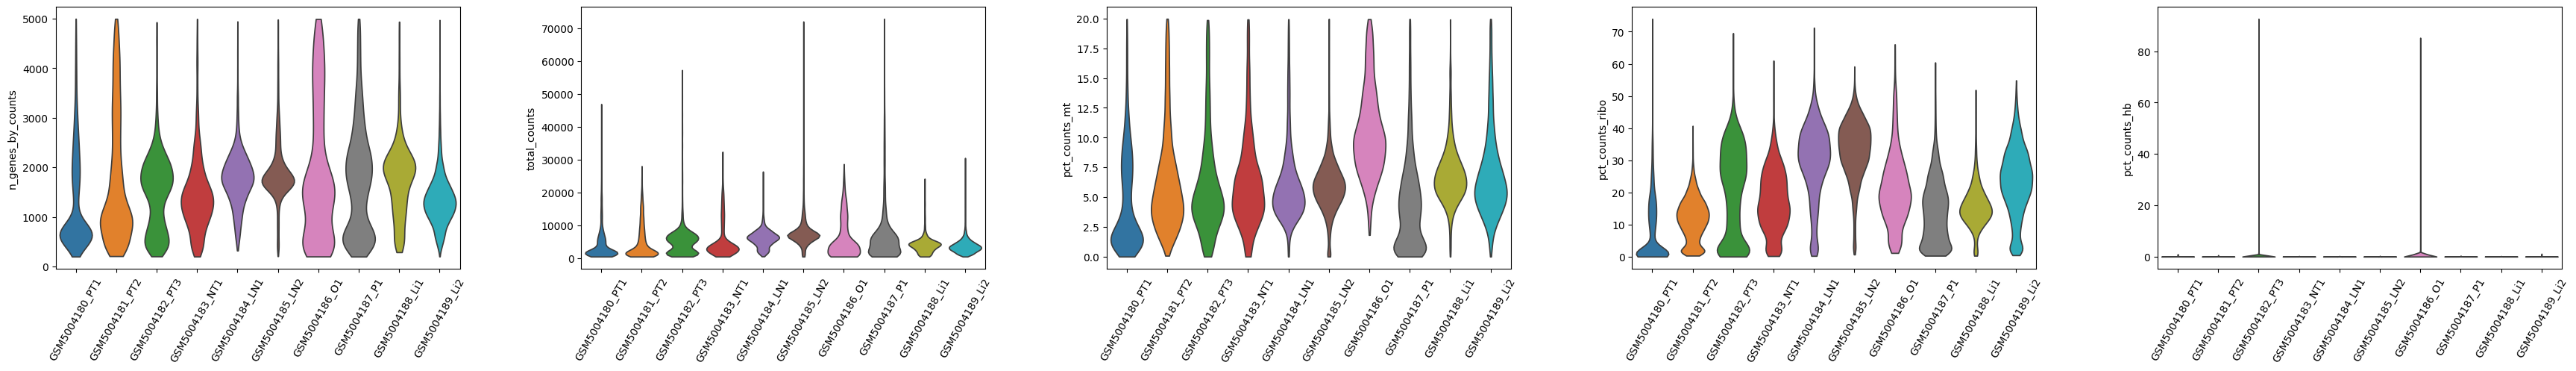

In [ ]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb"],
             groupby='sample', jitter=0.4, size=0, multi_panel=True, rotation=60)

/home/fugui/miniconda3/envs/r433/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:208: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


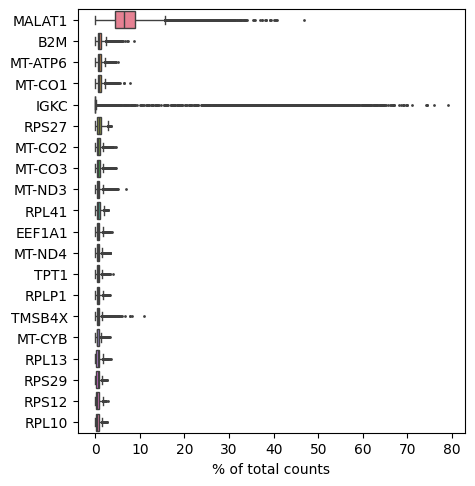

In [ ]:
sc.pl.highest_expr_genes(adata, n_top=20)

### Correction of ambient RNA (Optional)
For droplet based single cell RNA-seq experiments, a certain amount of background mRNAs is present in the dilution that gets distributed into the droplets with cells and sequenced along with them.
1. SoupX: R package
    Matthew D Young, Sam Behjati, SoupX removes ambient RNA contamination from droplet-based single-cell RNA sequencing data, GigaScience, Volume 9, Issue 12, December 2020, giaa151, https://doi.org/10.1093/gigascience/giaa151
2. DecontX
    Yang, S., Corbett, S.E., Koga, Y. et al. Decontamination of ambient RNA in single-cell RNA-seq with DecontX. Genome Biol 21, 57 (2020). https://doi.org/10.1186/s13059-020-1950-6

### Doublet detection

#### Scrublet
Samuel L. Wolock, Romain Lopez, and Allon M. Klein. Scrublet: computational identification of cell doublets in single-cell transcriptomic data. Cell Systems, 8(4):281–291.e9, apr 2019. URL: https://doi.org/10.1016/j.cels.2018.11.005, doi:10.1016/j.cels.2018.11.005

In [ ]:
%%time
sc.pp.scrublet(adata, batch_key="sample")
adata

CPU times: user 5min 8s, sys: 14.2 s, total: 5min 22s
Wall time: 2min 43s


AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'sample_colors', 'scrublet'

#### DoubletDetection
#### SOLO

#### scDblFinder
R package


### Normalization
1. shifted logarithm transformation: The shifted logarithm works beneficial for stabilizing variance for subsequent dimensionality reduction and identification of differentially expressed genes.
2. scran normalization: Scran was extensively tested and used for batch correction tasks.
    - scran R package
3. analytic approximation of Pearson residuals: suited for selecting biologically variable genes and identification of rare cell types.



In [ ]:
p1 = sns.histplot(adata.obs["total_counts"], bins=100, kde=False)

In [ ]:
%%time
adata.layers["counts"] = adata.X.copy()
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
adata

CPU times: user 567 ms, sys: 186 ms, total: 753 ms
Wall time: 752 ms


AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'sample_colors', 'scrublet', 'log1p'
    layers: 'counts'

In [ ]:
analytic_pearson = sc.experimental.pp.normalize_pearson_residuals(adata, inplace=False)
adata.layers["analytic_pearson_residuals"] = csr_matrix(analytic_pearson["X"])

In [ ]:
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt"])

In [ ]:
sc.pp.scale(adata, max_value=10)

### Feature selection
1. Traditional approaches
    - Coefficient of variation (highly variable genes)
    - Average expression level (highly expressed genes)
2. Deviance
    - base on raw counts
    - scry (R package)

In [ ]:
%%time
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample")
adata

CPU times: user 1.72 s, sys: 308 ms, total: 2.03 s
Wall time: 1.74 s


AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg'
    layers: 'counts'

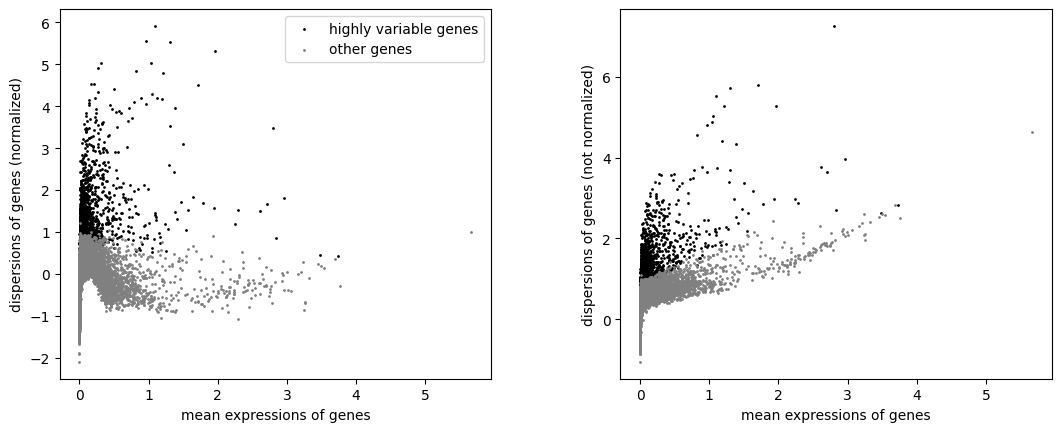

In [ ]:
sc.pl.highly_variable_genes(adata)

### Dimensionality Reduction
1. PCA: linear dimensionality reduction
2. t-SNE: non-linear dimensionality reduction
3. UMAP: non-linear dimensionality reduction


In [ ]:
%%time
sc.tl.pca(adata)
sc.pp.pca(adata, svd_solver="arpack", use_highly_variable=True)
adata

CPU times: user 5.04 s, sys: 7.3 ms, total: 5.05 s
Wall time: 2.44 s


AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'

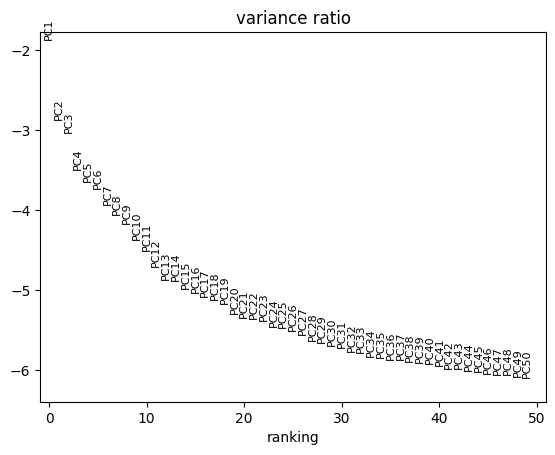

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

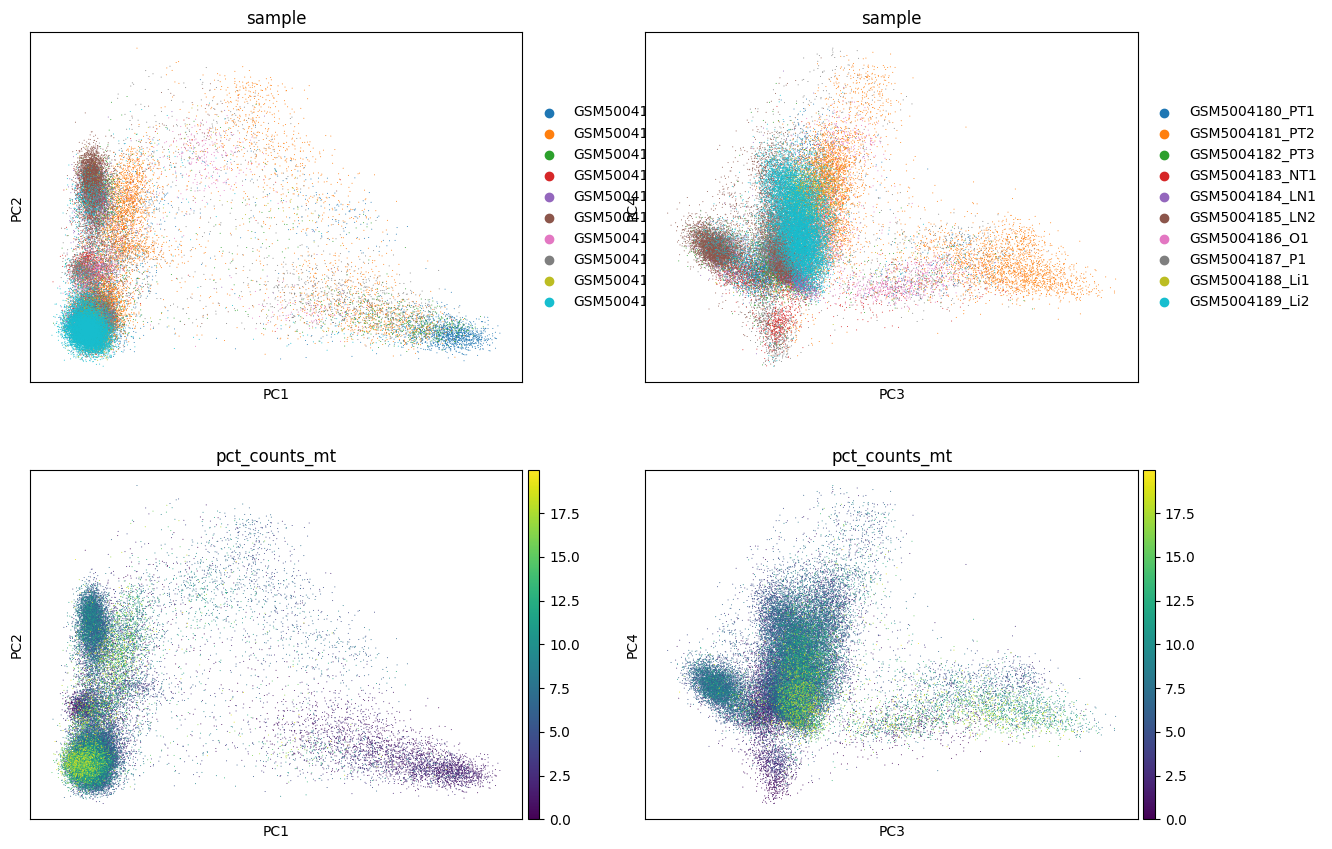

In [ ]:
sc.pl.pca(adata, color=["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
          dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)], ncols=2, size=2)
sc.pl.pca_scatter(adata, color="total_counts")

### Nearest neighbor graph constuction and visualization

In [ ]:
%%time
sc.pp.neighbors(adata)
adata

/home/fugui/miniconda3/envs/r433/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-02-15 22:48:20.069555: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-02-15 22:48:20.264889: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1739630900.324585   45751 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1739630900.340505   45751 cuda_blas.cc:141

CPU times: user 6.83 s, sys: 684 ms, total: 7.51 s
Wall time: 10.7 s


AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [ ]:
%%time
sc.tl.umap(adata)
adata

CPU times: user 49.3 s, sys: 38.6 ms, total: 49.3 s
Wall time: 17.1 s


AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [ ]:
sc.pl.umap(adata, color="total_counts")

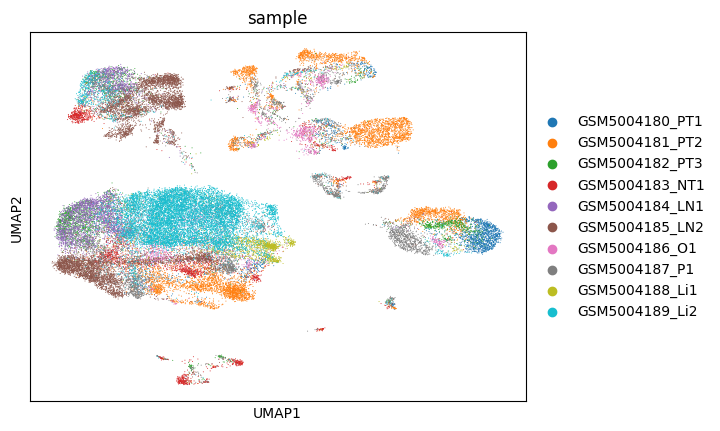

In [ ]:
sc.pl.umap(adata, color="sample", size=2)

In [ ]:
%%time
# Using the igraph implementation and a fixed number of iterations can be significantly faster, especially for larger datasets
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)
adata

CPU times: user 1.47 s, sys: 49.6 ms, total: 1.52 s
Wall time: 1.55 s


AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

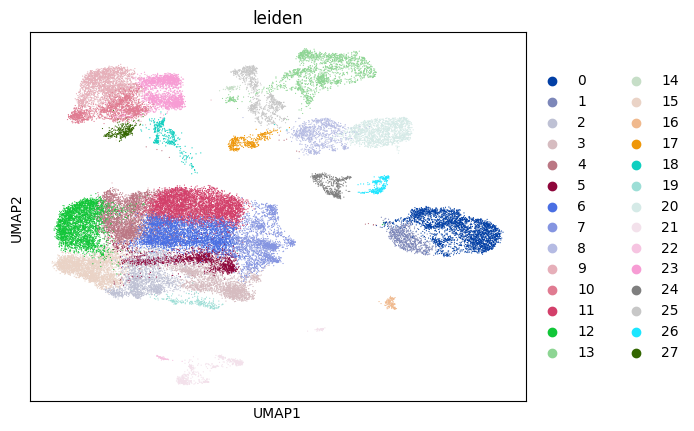

AnnData object with n_obs × n_vars = 42972 × 27544
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

In [ ]:
sc.pl.umap(adata, color=["leiden"])
adata

In [ ]:
sc.tl.tsne(adata, use_rep="X_pca")
sc.pl.tsne(adata, color="total_counts")

In [ ]:
sc.pl.umap(
    adata,
    color=["total_counts", "pct_counts_mt", "scDblFinder_score", "scDblFinder_class"],
)

### Clustering
This lower dimensional representation is, for example, determined with a principal-component analysis and the similarity scoring is then based on Euclidean distances
We first calculate a Euclidean distance matrix on the PC-reduced expression space for all cells and then connect each cell to its K most similar cells. Usually, K is set to values between 5 and 100 depending on the size of the dataset. 

Leiden: The Leiden algorithm is an improved version of the Louvain algorithm
Louvain: Louvain algorithm is no longer maintained

In [ ]:
sc.pp.neighbors(adata, n_pcs=30)
sc.tl.umap(adata)

In [ ]:
sc.tl.leiden(adata)

In [ ]:
sc.tl.leiden(adata, key_added="leiden_res0_25", resolution=0.25)
sc.tl.leiden(adata, key_added="leiden_res0_5", resolution=0.5)
sc.tl.leiden(adata, key_added="leiden_res1", resolution=1.0)

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden_res0_25", "leiden_res0_5", "leiden_res1"],
    legend_loc="on data",
)

### Cell Annotation


### Data Integration
1. batch effects
2. biological effects

method:
    1. Global models: ComBat
    2. Linear embedding models: mutual nearest neighbors (MNN), Seurat integration, Scanorama, FastMNN, Harmony
    3. Graph-based methods: Batch-Balanced k-Nearest Neighbor (BBKNN)
    4. Deep learning approaches: scVI, scANVI, scGen

![integration_overview_figure](https://www.sc-best-practices.org/_images/integration_overview_figure.jpeg)

metric for quantifying batch correction
    1. k-nearest-neighbor Batch-Effect Test (kBET)

Harmony and Seurat consistently perform well for simple batch correction tasks, and scVI, scGen, scANVI, and Scanorama perform well for more complex data integration tasks.

batch correction

data integration

In [ ]:
# Python packages
import anndata2ri
import bbknn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib
import scvi

# R interface
from rpy2.robjects import pandas2ri

pandas2ri.activate()
anndata2ri.activate()

%load_ext rpy2.ipython

In [ ]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="cell_ranger", batch_key="batch")
adata

In [ ]:
n_batches = adata.var["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches

In [ ]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
adata_hvg

#### scVI

In [ ]:
scvi.model.SCVI.setup_anndata(adata_scvi, layer="counts", batch_key=batch_key)
adata_scvi

In [ ]:
model_scvi = scvi.model.SCVI(adata_scvi)
model_scvi

In [ ]:
model_scvi.view_anndata_setup()

In [ ]:
max_epochs_scvi = np.min([round((20000 / adata.n_obs) * 400), 400])
max_epochs_scvi

In [ ]:
model_scvi.train()

In [ ]:
adata_scvi.obsm["X_scVI"] = model_scvi.get_latent_representation()

In [ ]:
sc.pp.neighbors(adata_scvi, use_rep="X_scVI")
sc.tl.umap(adata_scvi)
adata_scvi

In [ ]:
sc.pl.umap(adata_scvi, color=[label_key, batch_key], wspace=1)

#### scANVI
This is an extension of the scVI model that can incorporate cell identity label information as well as batch information.

In [ ]:
# Normally we would need to run scVI first but we have already done that here
# model_scvi = scvi.model.SCVI(adata_scvi) etc.
model_scanvi = scvi.model.SCANVI.from_scvi_model(
    model_scvi, labels_key=label_key, unlabeled_category="unlabelled"
)
print(model_scanvi)
model_scanvi.view_anndata_setup()

In [ ]:
max_epochs_scanvi = int(np.min([10, np.max([2, round(max_epochs_scvi / 3.0)])]))
model_scanvi.train(max_epochs=max_epochs_scanvi)

In [ ]:
max_epochs_scanvi = int(np.min([10, np.max([2, round(max_epochs_scvi / 3.0)])]))
model_scanvi.train(max_epochs=max_epochs_scanvi)

In [ ]:
adata_scanvi = adata_scvi.copy()
adata_scanvi.obsm["X_scANVI"] = model_scanvi.get_latent_representation()
sc.pp.neighbors(adata_scanvi, use_rep="X_scANVI")
sc.tl.umap(adata_scanvi)
sc.pl.umap(adata_scanvi, color=[label_key, batch_key], wspace=1)

#### BBKNN

In [ ]:
neighbors_within_batch = 25 if adata_hvg.n_obs > 100000 else 3
neighbors_within_batch

In [ ]:
adata_bbknn = adata_hvg.copy()
adata_bbknn.X = adata_bbknn.layers["logcounts"].copy()
sc.pp.pca(adata_bbknn)

In [ ]:
bbknn.bbknn(
    adata_bbknn, batch_key=batch_key, neighbors_within_batch=neighbors_within_batch
)
adata_bbknn

In [ ]:
sc.tl.umap(adata_bbknn)
sc.pl.umap(adata_bbknn, color=[label_key, batch_key], wspace=1)

#### MNN
R package Seurat

In [ ]:
adata_seurat = adata_hvg.copy()
# Convert categorical columns to strings
adata_seurat.obs[batch_key] = adata_seurat.obs[batch_key].astype(str)
adata_seurat.obs[label_key] = adata_seurat.obs[label_key].astype(str)
# Delete uns as this can contain arbitrary objects which are difficult to convert
del adata_seurat.uns
adata_seurat

## Inferring Trajectories

1. cluster and connections between these clusters identified


In [ ]:
sc.pp.filter_genes(adata, min_counts=20)
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata)

sc.tl.pca(adata)
sc.pp.neighbors(adata, n_pcs=10)

In [ ]:
sc.pl.scatter(adata, basis="tsne", color="clusters")

In [ ]:
sc.tl.diffmap(adata)